# EDA com download e exportação — League of Legends

Este notebook reproduz a análise de `arquivo-eda-original.ipynb` usando o dataset **League of Legends Diamond Ranked Games (10 min)**. Ele remove as células remanescentes do exemplo de Heart Disease, baixa o CSV público e exporta a versão tratada consumida pelo Streamlit.

- Fonte original: [Kaggle — League of Legends Diamond Ranked Games (10 min)](https://www.kaggle.com/datasets/bobbyscience/league-of-legends-diamond-ranked-games-10-min)
- Arquivo: `high_diamond_ranked_10min.csv`
- Unidade de análise: uma partida ranqueada Diamond/Master, observada aos 10 minutos.


## 1. Bibliotecas, caminhos e identidade visual

O notebook funciona tanto a partir da raiz do repositório quanto de `notebooks/`.


In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

%matplotlib inline
sns.set_theme(style="darkgrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "#d9e2d0"
COR_CONTEXTO = "#f2b84b"
COR_DESTAQUE = "#176b4d"
COR_ALERTA = "#b45309"

RAIZ = Path("..") if Path("../data").exists() else Path(".")
PASTA_RAW = RAIZ / "data" / "raw"
PASTA_CLEAN = RAIZ / "data" / "clean"
PASTA_RAW.mkdir(parents=True, exist_ok=True)
PASTA_CLEAN.mkdir(parents=True, exist_ok=True)


## 2. Download do dataset

A URL abaixo é um espelho público do arquivo disponibilizado originalmente no Kaggle. O CSV bruto é salvo em `data/raw/` e continua ignorado pelo Git; somente a versão tratada será versionada.


In [5]:
DATA_URL = (
    "https://raw.githubusercontent.com/juanfelipehdezm/"
    "LOL-league-Of-Legends/master/high_diamond_ranked_10min.csv"
)

df_raw = pd.read_csv(DATA_URL)
df_raw.to_csv(PASTA_RAW / "dataset.csv", index=False)
print(f"Dataset bruto: {df_raw.shape[0]:,} partidas × {df_raw.shape[1]} colunas")
df_raw.head()


Dataset bruto: 9,879 partidas × 40 colunas


,gameId,blueWins,blueWardsPlaced,blueWardsDestroyed,blueFirstBlood,blueKills,blueDeaths,blueAssists,blueEliteMonsters,blueDragons,...,redTowersDestroyed,redTotalGold,redAvgLevel,redTotalExperience,redTotalMinionsKilled,redTotalJungleMinionsKilled,redGoldDiff,redExperienceDiff,redCSPerMin,redGoldPerMin
0,4519157822,0,28,2,1,9,6,11,0,0,...,0,16567,6.8,17047,197,55,-643,8,19.7,1656.7
1,4523371949,0,12,1,0,5,5,5,0,0,...,1,17620,6.8,17438,240,52,2908,1173,24.0,1762.0
2,4521474530,0,15,0,0,7,11,4,1,1,...,0,17285,6.8,17254,203,28,1172,1033,20.3,1728.5
3,4524384067,0,43,1,0,4,5,5,1,0,...,0,16478,7.0,17961,235,47,1321,7,23.5,1647.8
4,4436033771,0,75,4,0,6,6,6,0,0,...,0,17404,7.0,18313,225,67,1004,-230,22.5,1740.4


## 3. Inspeção estrutural

Verificamos dimensão, tipos, duplicatas e ausências antes de transformar os dados.


In [6]:
display(df_raw.info())
print(f"Linhas duplicadas: {df_raw.duplicated().sum()}")
print(f"Valores ausentes: {int(df_raw.isna().sum().sum())}")
df_raw.describe().T


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9879 entries, 0 to 9878
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   gameId                        9879 non-null   int64  
 1   blueWins                      9879 non-null   int64  
 2   blueWardsPlaced               9879 non-null   int64  
 3   blueWardsDestroyed            9879 non-null   int64  
 4   blueFirstBlood                9879 non-null   int64  
 5   blueKills                     9879 non-null   int64  
 6   blueDeaths                    9879 non-null   int64  
 7   blueAssists                   9879 non-null   int64  
 8   blueEliteMonsters             9879 non-null   int64  
 9   blueDragons                   9879 non-null   int64  
 10  blueHeralds                   9879 non-null   int64  
 11  blueTowersDestroyed           9879 non-null   int64  
 12  blueTotalGold                 9879 non-null   int64  
 13  blu

None

Linhas duplicadas: 0
Valores ausentes: 0


,count,mean,std,min,25%,50%,75%,max
gameId,9879.0,4.500084e+09,2.757328e+07,4.295358e+09,4.483301e+09,4.510920e+09,4.521733e+09,4.527991e+09
blueWins,9879.0,4.990384e-01,5.000244e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00
blueWardsPlaced,9879.0,2.228829e+01,1.801918e+01,5.000000e+00,1.400000e+01,1.600000e+01,2.000000e+01,2.500000e+02
blueWardsDestroyed,9879.0,2.824881e+00,2.174998e+00,0.000000e+00,1.000000e+00,3.000000e+00,4.000000e+00,2.700000e+01
blueFirstBlood,9879.0,5.048082e-01,5.000022e-01,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
blueKills,9879.0,6.183925e+00,3.011028e+00,0.000000e+00,4.000000e+00,6.000000e+00,8.000000e+00,2.200000e+01
blueDeaths,9879.0,6.137666e+00,2.933818e+00,0.000000e+00,4.000000e+00,6.000000e+00,8.000000e+00,2.200000e+01
blueAssists,9879.0,6.645106e+00,4.064520e+00,0.000000e+00,4.000000e+00,6.000000e+00,9.000000e+00,2.900000e+01
blueEliteMonsters,9879.0,5.499544e-01,6.255265e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,2.000000e+00
blueDragons,9879.0,3.619800e-01,4.805974e-01,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00,1.000000e+00


## 4. Tratamento e enriquecimento

A análise original não exige imputação: a base não possui ausências. Mantemos as variáveis observadas aos 10 minutos e adicionamos rótulos legíveis e medidas derivadas usadas nos dashboards.


In [7]:
df = df_raw.drop_duplicates().copy()

df["team_label"] = df["blueWins"].map({0: "Time Vermelho", 1: "Time Azul"})
df["avg_level_band"] = pd.cut(
    df["blueAvgLevel"],
    bins=[-np.inf, 6.8, 7.0, 7.2, np.inf],
    labels=["Baixo", "Médio-baixo", "Médio-alto", "Alto"],
)
df["blueTotalGold_log"] = np.log1p(df["blueTotalGold"])
df["blueObjectives"] = (
    df["blueDragons"] + df["blueHeralds"] + df["blueTowersDestroyed"]
)
df["redObjectives"] = (
    df["redDragons"] + df["redHeralds"] + df["redTowersDestroyed"]
)

print(df[["blueWins", "team_label", "avg_level_band"]].head())
print(f"Base tratada: {df.shape[0]:,} partidas × {df.shape[1]} colunas")


   blueWins     team_label avg_level_band
0         0  Time Vermelho          Baixo
1         0  Time Vermelho          Baixo
2         0  Time Vermelho          Baixo
3         0  Time Vermelho    Médio-baixo
4         0  Time Vermelho    Médio-baixo
Base tratada: 9,879 partidas × 45 colunas


## 5. Variáveis da EDA original

`blueWins` é o desfecho: `1` representa vitória do time azul e `0`, vitória do time vermelho. As variáveis quantitativas seguem a seleção feita no notebook original.


In [8]:
VARS_QUANT = [
    "blueWardsPlaced", "blueWardsDestroyed", "blueKills", "blueDeaths",
    "blueAssists", "blueEliteMonsters", "blueTotalGold", "blueAvgLevel",
    "blueTotalExperience", "blueTotalMinionsKilled",
    "blueTotalJungleMinionsKilled", "blueGoldDiff", "blueExperienceDiff",
    "blueCSPerMin", "blueGoldPerMin", "redWardsPlaced",
    "redWardsDestroyed", "redKills", "redDeaths", "redAssists",
    "redEliteMonsters", "redTotalGold", "redAvgLevel",
    "redTotalExperience", "redTotalMinionsKilled",
    "redTotalJungleMinionsKilled", "redGoldDiff", "redExperienceDiff",
    "redCSPerMin", "redGoldPerMin",
]

VARS_QUALI = [
    "blueWins", "blueFirstBlood", "blueDragons", "blueHeralds",
    "blueTowersDestroyed", "redFirstBlood", "redDragons",
    "redHeralds", "redTowersDestroyed",
]

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()
desc.round(2)


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
blueWardsPlaced,9879.0,22.29,18.02,5.0,14.00,16.0,20.00,250.0,4.14,23.44
blueWardsDestroyed,9879.0,2.82,2.17,0.0,1.00,3.0,4.00,27.0,2.85,17.20
blueKills,9879.0,6.18,3.01,0.0,4.00,6.0,8.00,22.0,0.54,0.26
blueDeaths,9879.0,6.14,2.93,0.0,4.00,6.0,8.00,22.0,0.51,0.21
blueAssists,9879.0,6.65,4.06,0.0,4.00,6.0,9.00,29.0,0.89,1.16
blueEliteMonsters,9879.0,0.55,0.63,0.0,0.00,0.0,1.00,2.0,0.69,-0.50
blueTotalGold,9879.0,16503.46,1535.45,10730.0,15415.50,16398.0,17459.00,23701.0,0.47,0.48
blueAvgLevel,9879.0,6.92,0.31,4.6,6.80,7.0,7.20,8.0,-0.34,1.12
blueTotalExperience,9879.0,17928.11,1200.52,10098.0,17168.00,17951.0,18724.00,22224.0,-0.25,0.68
blueTotalMinionsKilled,9879.0,216.70,21.86,90.0,202.00,218.0,232.00,283.0,-0.27,0.17


## 6. Distribuições por resultado

A comparação dá atenção a ouro, abates, experiência e objetivos — vantagens centrais da análise original aos dez minutos.


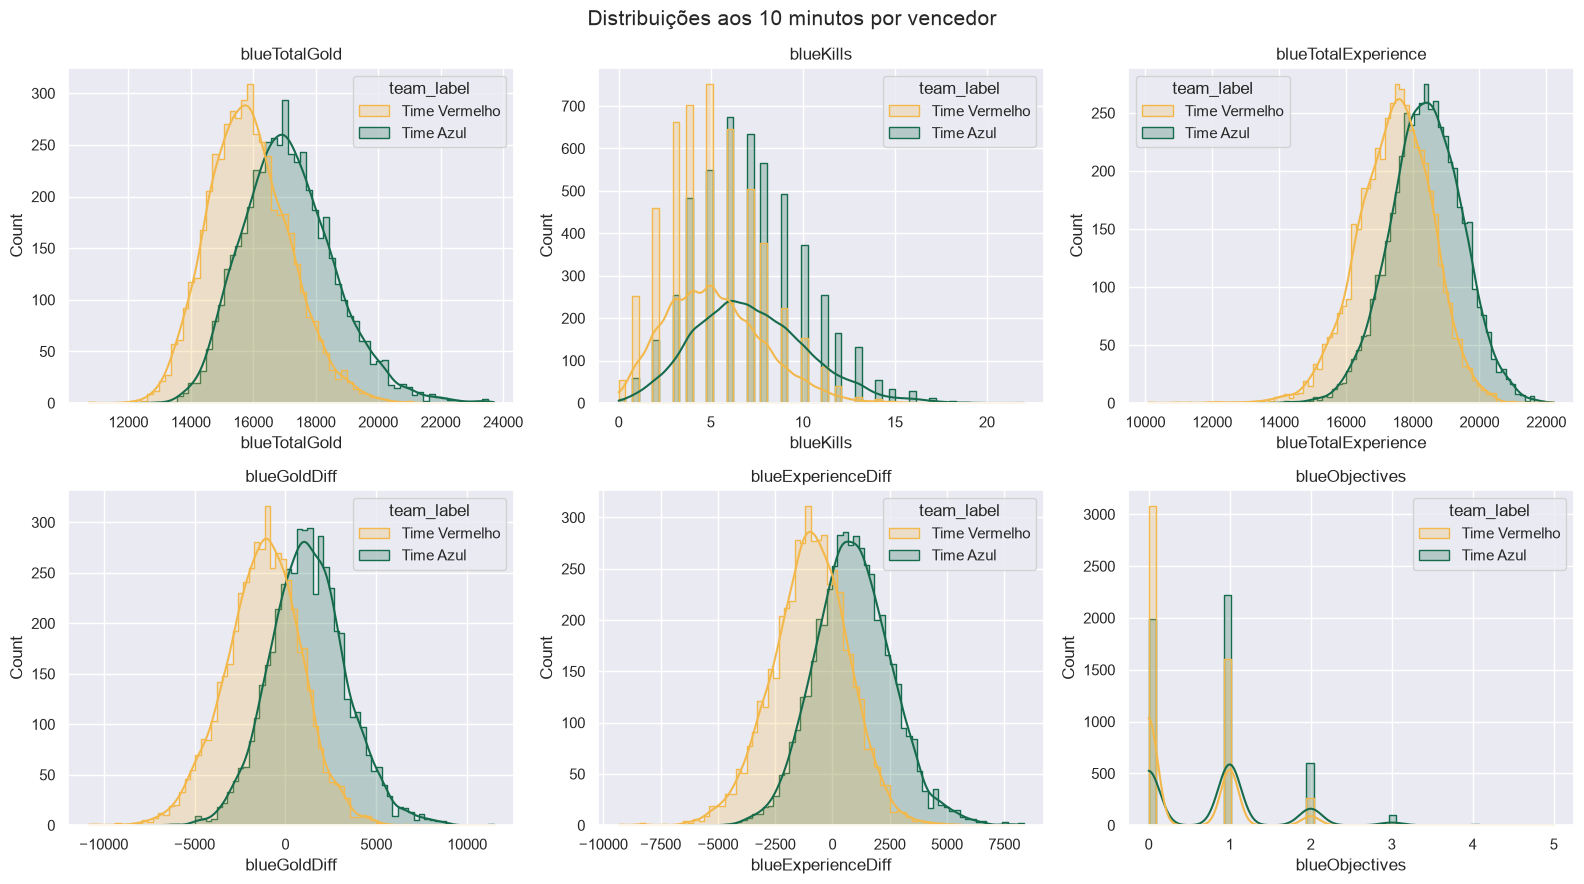

In [9]:
variaveis_foco = [
    "blueTotalGold", "blueKills", "blueTotalExperience",
    "blueGoldDiff", "blueExperienceDiff", "blueObjectives",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, coluna in zip(axes.ravel(), variaveis_foco):
    sns.histplot(
        data=df, x=coluna, hue="team_label", kde=True, element="step",
        palette={"Time Vermelho": COR_CONTEXTO, "Time Azul": COR_DESTAQUE}, ax=ax,
    )
    ax.set_title(coluna)
fig.suptitle("Distribuições aos 10 minutos por vencedor", fontsize=15)
plt.tight_layout()
plt.show()


## 7. Correlação de Spearman

Spearman é mantida por coerência com a EDA original e por não exigir normalidade das distribuições.


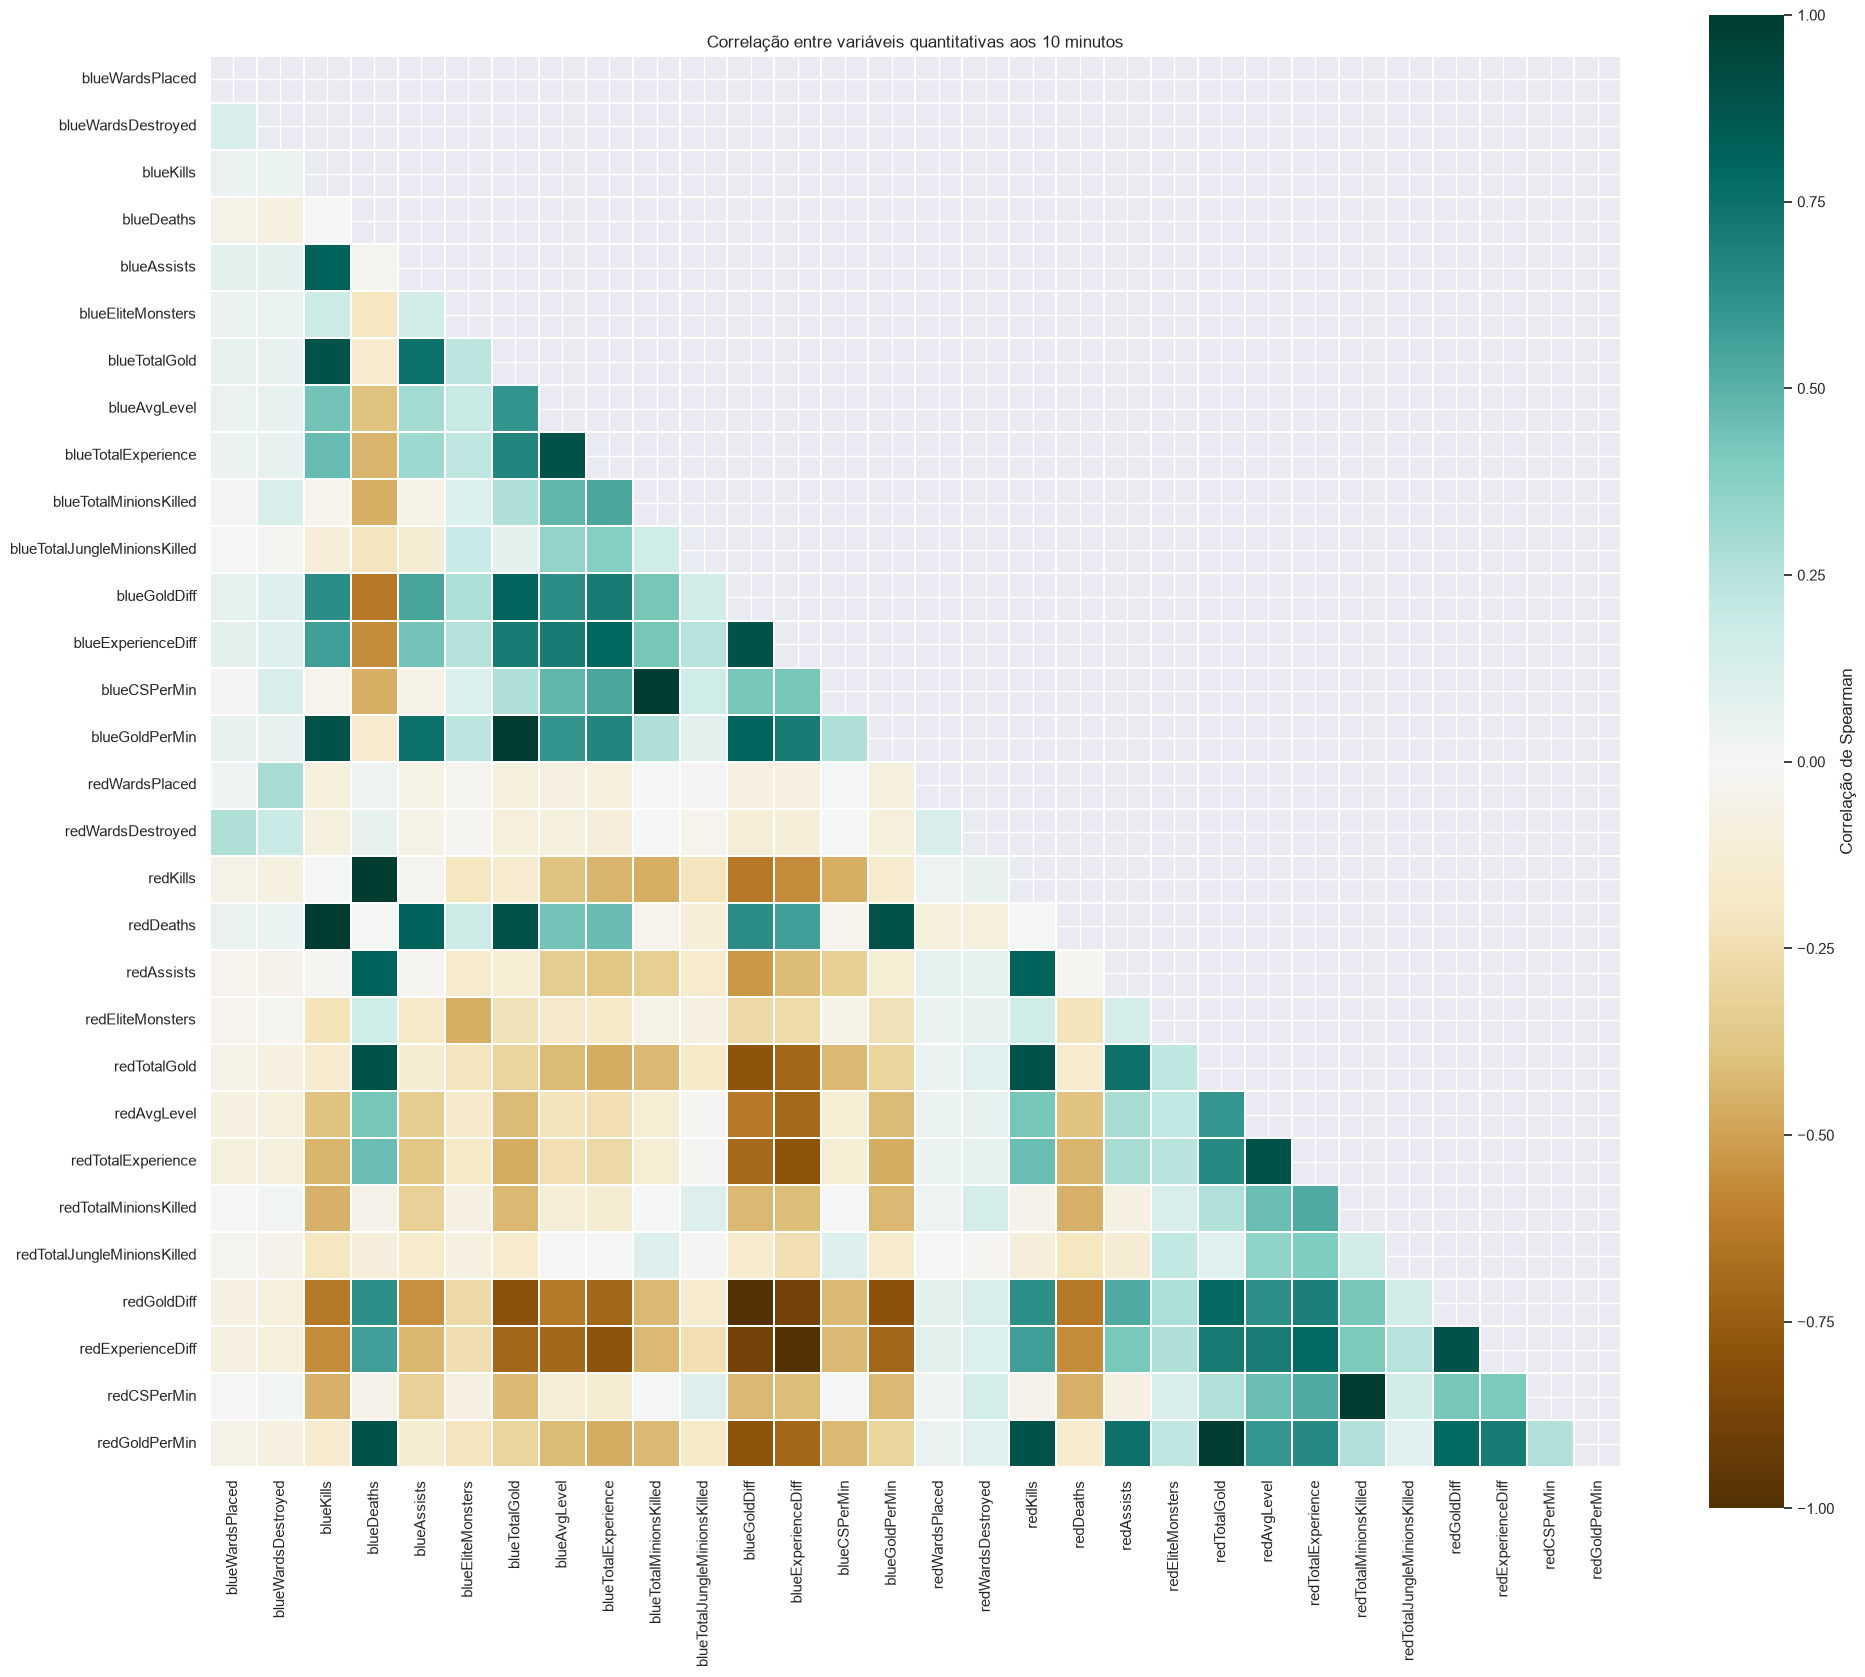

In [10]:
corr_spearman = df[VARS_QUANT].corr(method="spearman")
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(20, 17))
sns.heatmap(
    corr_spearman, mask=mask, cmap="BrBG", center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.2, cbar_kws={"label": "Correlação de Spearman"},
)
plt.title("Correlação entre variáveis quantitativas aos 10 minutos")
plt.tight_layout()
plt.show()


## 8. Relações com o resultado da partida

Comparamos as vantagens do time azul aos dez minutos com o resultado final. Isso preserva a pergunta central do notebook original: quais sinais do início da partida mais separam vitórias e derrotas?


In [11]:
resumo_resultado = (
    df.groupby("team_label", observed=True)
    .agg(
        partidas=("gameId", "count"),
        ouro_azul_medio=("blueTotalGold", "mean"),
        diferenca_ouro_media=("blueGoldDiff", "mean"),
        diferenca_xp_media=("blueExperienceDiff", "mean"),
        abates_azuis_medios=("blueKills", "mean"),
        objetivos_azuis_medios=("blueObjectives", "mean"),
    )
    .round(2)
)
resumo_resultado


,partidas,ouro_azul_medio,diferenca_ouro_media,diferenca_xp_media,abates_azuis_medios,objetivos_azuis_medios
team_label,,,,,,
Time Azul,4930,17145.26,1270.72,908.27,7.20,0.77
Time Vermelho,4949,15864.11,-1237.07,-971.90,5.17,0.43


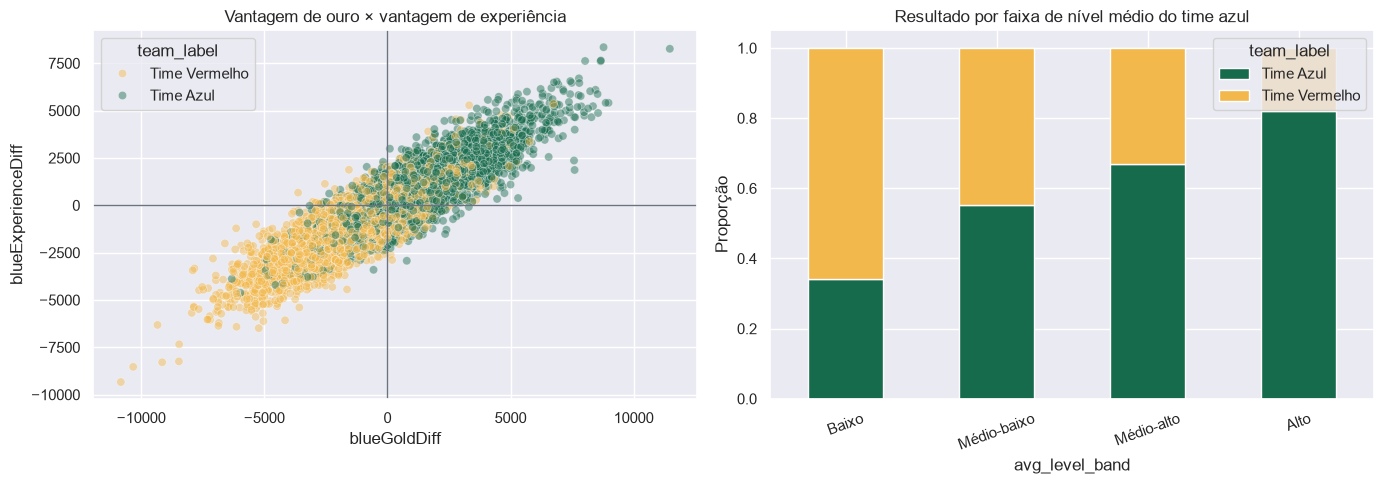

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=df, x="blueGoldDiff", y="blueExperienceDiff", hue="team_label",
    palette={"Time Vermelho": COR_CONTEXTO, "Time Azul": COR_DESTAQUE},
    alpha=0.45, ax=axes[0],
)
axes[0].axvline(0, color="#6b7280", linewidth=1)
axes[0].axhline(0, color="#6b7280", linewidth=1)
axes[0].set_title("Vantagem de ouro × vantagem de experiência")

prop_nivel = pd.crosstab(df["avg_level_band"], df["team_label"], normalize="index")
prop_nivel.plot(
    kind="bar", stacked=True, color=[COR_DESTAQUE, COR_CONTEXTO], ax=axes[1]
)
axes[1].set_title("Resultado por faixa de nível médio do time azul")
axes[1].set_ylabel("Proporção")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()


## 9. Planejamento e validação das métricas do Dashboard 2

As métricas usam apenas informações disponíveis aos dez minutos e comunicam equilíbrio, vantagem econômica, combate e controle de objetivos.


In [13]:
taxa_vitoria_azul = df["blueWins"].mean() * 100
diferenca_ouro_media = df["blueGoldDiff"].mean()
diferenca_abates_media = (df["blueKills"] - df["redKills"]).mean()
controle_objetivos_azul = (
    df["blueObjectives"] / (df["blueObjectives"] + df["redObjectives"]).replace(0, np.nan)
).mean() * 100

print(f"Vitórias do time azul: {taxa_vitoria_azul:.1f}%")
print(f"Diferença média de ouro (azul - vermelho): {diferenca_ouro_media:+.1f}")
print(f"Diferença média de abates (azul - vermelho): {diferenca_abates_media:+.2f}")
print(f"Participação azul nos objetivos disputados: {controle_objetivos_azul:.1f}%")


Vitórias do time azul: 49.9%
Diferença média de ouro (azul - vermelho): +14.4
Diferença média de abates (azul - vermelho): +0.05
Participação azul nos objetivos disputados: 48.9%


In [14]:
resumo_faixa = (
    df.groupby("avg_level_band", observed=True, as_index=False)
    .agg(
        partidas=("gameId", "count"),
        taxa_vitoria_azul=("blueWins", lambda serie: serie.mean() * 100),
        diferenca_ouro_media=("blueGoldDiff", "mean"),
        diferenca_xp_media=("blueExperienceDiff", "mean"),
    )
)
resumo_faixa.round(2)


,avg_level_band,partidas,taxa_vitoria_azul,diferenca_ouro_media,diferenca_xp_media
0,Baixo,4601,34.08,-1376.13,-1221.63
1,Médio-baixo,2611,55.19,457.95,307.56
2,Médio-alto,1779,67.00,1525.75,1282.90
3,Alto,888,82.09,2887.36,2481.16


## 10. Exportação

A versão tratada é a fonte única do `app.py`. O arquivo mantém todas as colunas originais e acrescenta apenas os campos derivados documentados acima.


In [15]:
df.to_csv(PASTA_CLEAN / "dataset.csv", index=False)

print(f"Raw salvo em:   {PASTA_RAW / 'dataset.csv'} — {df_raw.shape}")
print(f"Clean salvo em: {PASTA_CLEAN / 'dataset.csv'} — {df.shape}")
print("Campos derivados:", [
    "team_label", "avg_level_band", "blueTotalGold_log",
    "blueObjectives", "redObjectives",
])


Raw salvo em:   ../data/raw/dataset.csv — (9879, 40)
Clean salvo em: ../data/clean/dataset.csv — (9879, 45)
Campos derivados: ['team_label', 'avg_level_band', 'blueTotalGold_log', 'blueObjectives', 'redObjectives']


## Síntese

1. A base reúne partidas ranqueadas de alto nível observadas aos dez minutos, sem valores ausentes.
2. Diferenças de ouro e experiência representam a vantagem relativa entre os times e são mais informativas que totais isolados.
3. Abates, experiência, ouro e objetivos permitem comparar domínio de combate, crescimento econômico e controle de mapa.
4. A variável `blueWins` conecta os sinais iniciais ao vencedor final sem transformar associação em causalidade.
5. O dashboard deve permitir filtrar cenários e comparar as distribuições dos dois vencedores, mantendo as limitações observacionais do dataset.
